## Programming Exercise 8: Anomaly Detection and Recommender Systems

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import scipy.io #Used to load the OCTAVE *.mat files
import scipy.optimize #Use for fmincg

### 1 Anomaly detection

In [2]:
datafile = 'data/ex8data1.mat'
mat = scipy.io.loadmat( datafile )
X = mat['X']
ycv = mat['yval']
Xcv = mat['Xval']

In [3]:
# Visualize the data
def plotData(myX, newFig=False):
    if newFig:
        plt.figure(figsize=(8,6))
    plt.plot(myX[:,0],myX[:,1],'b+')
    plt.xlabel('Latency [ms]',fontsize=16)
    plt.ylabel('Throughput [mb/s]',fontsize=16)
    plt.grid(True)

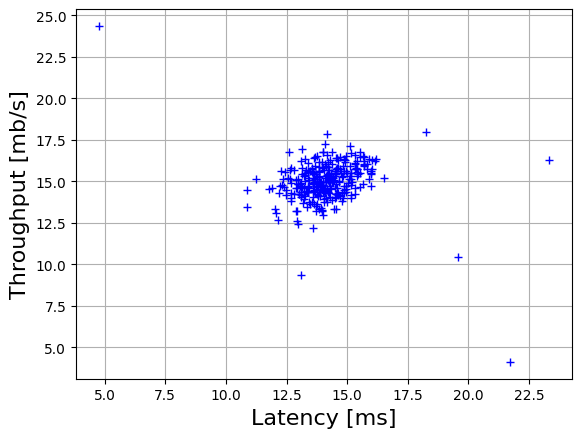

In [4]:
plotData(X)

#### 1.1 Gaussian distribution

In [5]:
def gaus(myX, mymu, mysig2):
    """
    Function to compute the gaussian return values for a feature
    matrix, myX, given the already computed mu vector and sigma matrix.
    If sigma is a vector, it is turned into a diagonal matrix
    Uses a loop over rows; I didn't quite figure out a vectorized implementation.
    """
    m = myX.shape[0]
    n = myX.shape[1]
    if np.ndim(mysig2) == 1:
        mysig2 = np.diag(mysig2)

    norm = 1./(np.power((2*np.pi), n/2)*np.sqrt(np.linalg.det(mysig2)))
    myinv = np.linalg.inv(mysig2)
    myexp = np.zeros((m,1))
    for irow in range(m):
        xrow = myX[irow]
        myexp[irow] = np.exp(-0.5*((xrow-mymu).T).dot(myinv).dot(xrow-mymu))
    return norm*myexp


#### 1.2 Estimating parameters for a Gaussian

In [6]:
def getGaussianParams(myX,useMultivariate = True):
    """
    Function that given a feature matrix X that is (m x n)
    returns a mean vector and a sigmasquared vector that are
    both (n x 1) in shape.
    This can do it either as a 1D gaussian for each feature,
    or as a multivariate gaussian.
    """
    m = myX.shape[0]
    mu = np.mean(myX,axis=0)
    if not useMultivariate:
        sigma2 = np.sum(np.square(myX-mu),axis=0)/float(m)
        return mu, sigma2
    else:
        sigma2 = ((myX-mu).T.dot(myX-mu))/float(m)
        return mu, sigma2

In [7]:
mu, sig2 = getGaussianParams(X, useMultivariate = True)

##### 1.2.1 Visualizing the Gaussian probability contours

In [8]:
def plotContours(mymu, mysigma2, newFig=False, useMultivariate = True):
    delta = .5
    myx = np.arange(0,30,delta)
    myy = np.arange(0,30,delta)
    meshx, meshy = np.meshgrid(myx, myy)
    coord_list = [ entry.ravel() for entry in (meshx, meshy) ]
    points = np.vstack(coord_list).T
    myz = gaus(points, mymu, mysigma2)
    #if not useMultivariate:
    #    myz = gausOrthog(points, mymu, mysigma2)
    #else: myz = gausMV(points, mymu, mysigma2)
    myz = myz.reshape((myx.shape[0],myx.shape[0]))

    if newFig: plt.figure(figsize=(6,4))
    
    cont_levels = [10**exp for exp in range(-20,0,3)]
    mycont = plt.contour(meshx, meshy, myz, levels=cont_levels)

    plt.title('Gaussian Contours',fontsize=16)

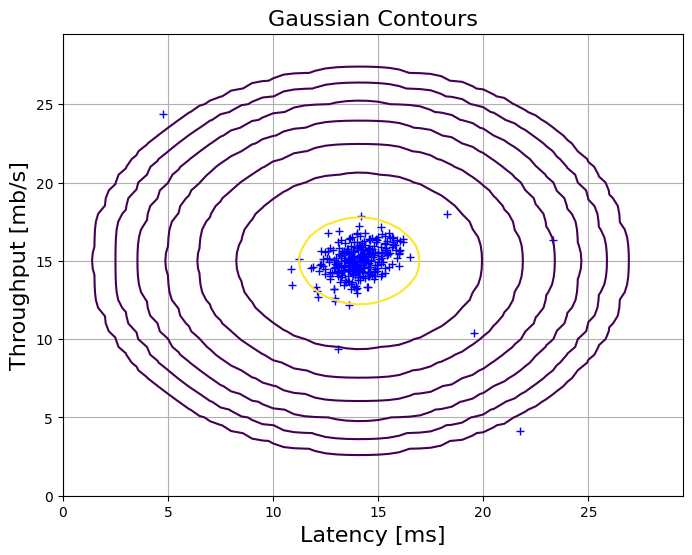

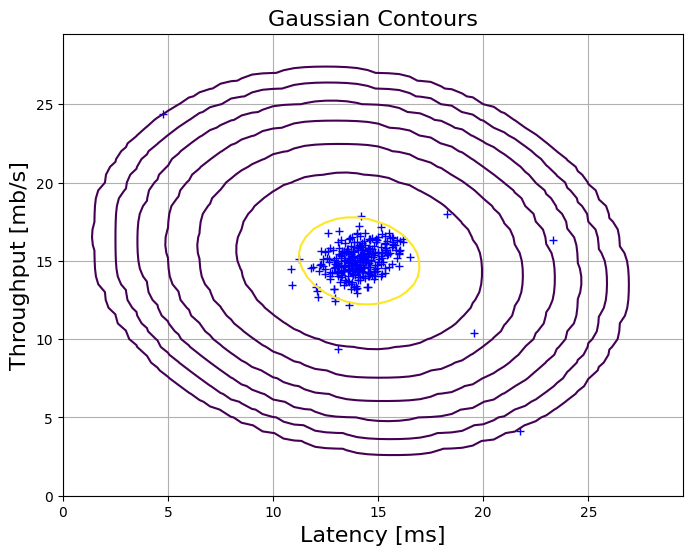

In [9]:
# First contours without using multivariate gaussian:
plotData(X, newFig=True)
useMV = False
plotContours(*getGaussianParams(X, useMV), newFig=False, useMultivariate = useMV)

# Then contours with multivariate gaussian:
plotData(X, newFig=True)
useMV = True
plotContours(*getGaussianParams(X, useMV), newFig=False, useMultivariate = useMV)

#### 1.3 Selecting the threshold, $\epsilon$

In [20]:
def computeF1(predVec, trueVec):
    """
    F1 = 2 * (P*R)/(P+R)
    where P is precision, R is recall
    Precision = "of all predicted y=1, what fraction had true y=1"
    Recall = "of all true y=1, what fraction predicted y=1?
    Note predictionVec and trueLabelVec should be boolean vectors.
    """
    #print predVec.shape
    #print trueVec.shape
    #assert predVec.shape == trueVec.shape
    
    P, R = 0., 0.

    trueVec = np.asarray(trueVec).flatten()
    predVec = np.asarray(predVec).flatten()

    TP = np.sum((trueVec == 1) & (predVec == 1))

    if np.sum(predVec):
        P = TP / np.sum(predVec)

    if np.sum(trueVec):
        R = TP / np.sum(trueVec)

    return 2 * P * R / (P + R) if (P + R) else 0

In [21]:
def selectThreshold(myycv, mypCVs):
    """
    Function to select the best epsilon value from the CV set
    by looping over possible epsilon values and computing the F1
    score for each.
    """
    # Make a list of possible epsilon values
    nsteps = 1000
    epses = np.linspace(np.min(mypCVs),np.max(mypCVs),nsteps)
    
    # Compute the F1 score for each epsilon value, and store the best 
    # F1 score (and corresponding best epsilon)
    bestF1, bestEps = 0, 0
    trueVec = (myycv == 1).flatten()
    for eps in epses:
        predVec = mypCVs < eps
        thisF1 = computeF1(predVec, trueVec)
        if thisF1 > bestF1:
            bestF1 = thisF1
            bestEps = eps
            
    print("Best F1 is %f, best eps is %0.4g."%(bestF1,bestEps))
    return bestF1, bestEps
        

In [22]:
# Using the gaussian parameters from the full training set,
# figure out the p-value for each point in the CV set
pCVs = gaus(Xcv, mu, sig2)

#You should see a value for epsilon of about 8.99e-05.
bestF1, bestEps = selectThreshold(ycv,pCVs)

Best F1 is 0.875000, best eps is 9.075e-05.


In [25]:
def plotAnomalies(myX, mybestEps, newFig = False, useMultivariate = True):
    ps = gaus(myX, *getGaussianParams(myX, useMultivariate))
    anoms = np.array([myX[x] for x in range(myX.shape[0]) if ps[x] < mybestEps])
    if newFig: plt.figure(figsize=(6,4))
    plt.scatter(anoms[:,0],anoms[:,1], s=80, facecolors='none', edgecolors='r')

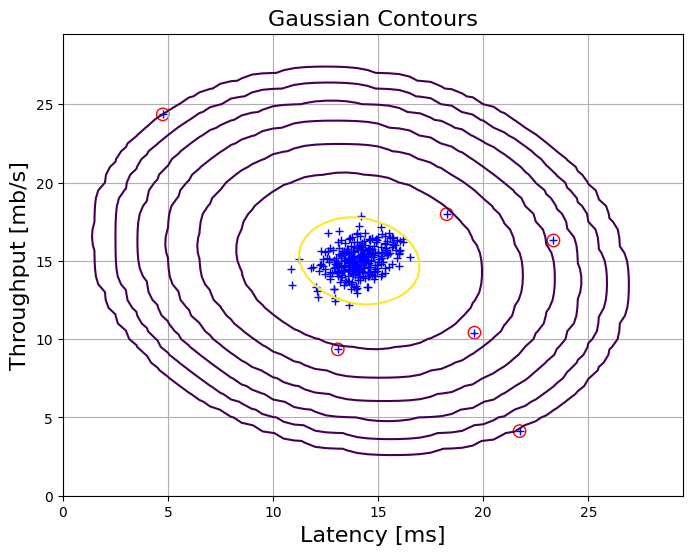

In [26]:
plotData(X, newFig=True)
plotContours(mu, sig2, newFig=False, useMultivariate=True)
plotAnomalies(X, bestEps, newFig=False, useMultivariate=True)

#### 1.4 High dimensional dataset

In [28]:
datafile = 'data/ex8data2.mat'
mat = scipy.io.loadmat( datafile )
Xpart2 = mat['X']
ycvpart2 = mat['yval']
Xcvpart2 = mat['Xval']
print('Xpart2 shape is ', Xpart2.shape)

Xpart2 shape is  (1000, 11)


In [30]:
mu, sig2 = getGaussianParams(Xpart2, useMultivariate=False)
ps = gaus(Xpart2, mu, sig2)
psCV = gaus(Xcvpart2, mu, sig2)

# Using the gaussian parameters from the full training set,
# figure out the p-value for each point in the CV set
pCVs = gaus(Xcvpart2, mu, sig2)

# You should see a value epsilon of about 1.38e-18, and 117 anomalies found.
bestF1, bestEps = selectThreshold(ycvpart2,pCVs)
anoms = [Xpart2[x] for x in range(Xpart2.shape[0]) if ps[x] < bestEps]
print('# of anomalies found: ',len(anoms))

Best F1 is 0.615385, best eps is 1.379e-18.
# of anomalies found:  117


### 2 Recommender Systems

#### 2.1 Movie ratings dataset

In [31]:
datafile = 'data/ex8_movies.mat'
mat = scipy.io.loadmat( datafile )
Y = mat['Y']
R = mat['R']

nm, nu = Y.shape
# Y is 1682x943 containing ratings (1-5) of 1682 movies on 943 users
# a rating of 0 means the movie wasn't rated
# R is 1682x943 containing R(i,j) = 1 if user j gave a rating to movie i

Average rating for movie 1 (Toy Story): 3.88


Text(0.5, 0, 'Users (943)')

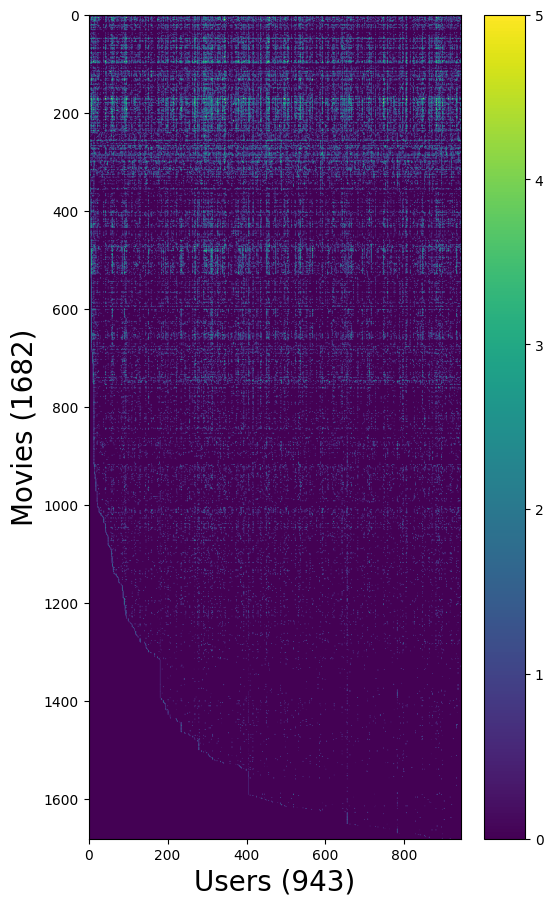

In [36]:
# Average rating for Toy Story (movie index 0), using ratings that exist.
toy_story_ratings = Y[0, R[0, :] != 0]
print('Average rating for movie 1 (Toy Story): %0.2f' % np.mean(toy_story_ratings))

# Visualize the ratings matrix.
fig = plt.figure(figsize=(6, 6 * (1682.0 / 943.0)))
plt.imshow(Y, aspect='auto')
plt.colorbar()
plt.ylabel('Movies (%d)' % nm, fontsize=20)
plt.xlabel('Users (%d)' % nu, fontsize=20)

In [37]:
# Throughout this part of the exercise, you will also be 
# working with the matrices, X and Theta
# The i-th row of X corresponds to the feature vector x(i) for the i-th movie, 
# and the j-th row of Theta corresponds to one parameter vector θ(j), for the j-th user. 
# Both x(i) and θ(j) are n-dimensional vectors. For the purposes of this exercise, 
# you will use n = 100, and therefore, x(i) ∈ R100 and θ(j) ∈ R100. Correspondingly, 
# X is a nm × 100 matrix and Theta is a nu × 100 matrix.

#### 2.2 Collaborative filtering learning algorithm

In [40]:
# Read in the movie parameter matrices.
datafile = 'data/ex8_movieParams.mat'
mat = scipy.io.loadmat(datafile)
X = mat['X']
Theta = mat['Theta']
nu = int(np.asarray(mat['num_users']).item())
nm = int(np.asarray(mat['num_movies']).item())
nf = int(np.asarray(mat['num_features']).item())

# For now, reduce the data set size so this runs faster.
nu, nm, nf = 4, 5, 3
X = X[:nm, :nf]
Theta = Theta[:nu, :nf]
Y = Y[:nm, :nu]
R = R[:nm, :nu]

In [41]:
# The "parameters" we are minimizing are both the elements of the
# X matrix (nm*nf) and of the Theta matrix (nu*nf)
# To use off-the-shelf minimizers we need to flatten these matrices
# into one long array
def flattenParams(myX, myTheta):
    """
    Hand this function an X matrix and a Theta matrix and it will flatten
    it into into one long (nm*nf + nu*nf,1) shaped numpy array
    """
    return np.concatenate((myX.flatten(),myTheta.flatten()))

# A utility function to re-shape the X and Theta will probably come in handy
def reshapeParams(flattened_XandTheta, mynm, mynu, mynf):
    assert flattened_XandTheta.shape[0] == int(nm*nf+nu*nf)
    
    reX = flattened_XandTheta[:int(mynm*mynf)].reshape((mynm,mynf))
    reTheta = flattened_XandTheta[int(mynm*mynf):].reshape((mynu,mynf))
    
    return reX, reTheta

##### 2.2.1 Collaborative filtering cost function and 2.2.3 Regularized cost function

In [42]:
def cofiCostFunc(myparams, myY, myR, mynu, mynm, mynf, mylambda = 0.):
    
    # Unfold the X and Theta matrices from the flattened params
    myX, myTheta = reshapeParams(myparams, mynm, mynu, mynf)
  
    # Note: 
    # X Shape is (nm x nf), Theta shape is (nu x nf), Y and R shape is (nm x nu)
    # Behold! Complete vectorization
    
    # First dot theta and X together such that you get a matrix the same shape as Y
    term1 = myX.dot(myTheta.T)
    
    # Then element-wise multiply that matrix by the R matrix
    # so only terms from movies which that user rated are counted in the cost
    term1 = np.multiply(term1,myR)
    
    # Then subtract the Y- matrix (which has 0 entries for non-rated
    # movies by each user, so no need to multiply that by myR... though, if
    # a user could rate a movie "0 stars" then myY would have to be element-
    # wise multiplied by myR as well) 
    # also square that whole term, sum all elements in the resulting matrix,
    # and multiply by 0.5 to get the cost
    cost = 0.5 * np.sum( np.square(term1-myY) )
    
    # Regularization stuff
    cost += (mylambda/2.) * np.sum(np.square(myTheta))
    cost += (mylambda/2.) * np.sum(np.square(myX))
    
    return cost

In [43]:
# "...run your cost function. You should expect to see an output of 22.22."
print('Cost with nu = 4, nm = 5, nf = 3 is %0.2f.' % \
    cofiCostFunc(flattenParams(X,Theta),Y,R,nu,nm,nf))
    
# "...with lambda = 1.5 you should expect to see an output of 31.34."
print('Cost with nu = 4, nm = 5, nf = 3 (and lambda = 1.5) is %0.2f.' % \
    cofiCostFunc(flattenParams(X,Theta),Y,R,nu,nm,nf,mylambda=1.5))

Cost with nu = 4, nm = 5, nf = 3 is 22.22.
Cost with nu = 4, nm = 5, nf = 3 (and lambda = 1.5) is 31.34.


##### 2.2.2 Collaborative filtering gradient and 2.2.4 Regularized gradient

In [44]:
# Remember: use the exact same input arguments for gradient function
# as for the cost function (the off-the-shelf minimizer requires this)
def cofiGrad(myparams, myY, myR, mynu, mynm, mynf, mylambda = 0.):
    
    # Unfold the X and Theta matrices from the flattened params
    myX, myTheta = reshapeParams(myparams, mynm, mynu, mynf)

    # First the X gradient term 
    # First dot theta and X together such that you get a matrix the same shape as Y
    term1 = myX.dot(myTheta.T)
    # Then multiply this term by myR to remove any components from movies that
    # weren't rated by that user
    term1 = np.multiply(term1,myR)
    # Now subtract the y matrix (which already has 0 for nonrated movies)
    term1 -= myY
    # Lastly dot this with Theta such that the resulting matrix has the
    # same shape as the X matrix
    Xgrad = term1.dot(myTheta)
    
    # Now the Theta gradient term (reusing the "term1" variable)
    Thetagrad = term1.T.dot(myX)

    # Regularization stuff
    Xgrad += mylambda * myX
    Thetagrad += mylambda * myTheta
    
    return flattenParams(Xgrad, Thetagrad)

In [46]:
#Let's check my gradient computation real quick:
def checkGradient(myparams, myY, myR, mynu, mynm, mynf, mylambda = 0.):
    
    print('Numerical Gradient \t cofiGrad \t\t Difference')
    
    # Compute a numerical gradient with an epsilon perturbation vector
    myeps = 0.0001
    nparams = len(myparams)
    epsvec = np.zeros(nparams)
    # These are my implemented gradient solutions
    mygrads = cofiGrad(myparams,myY,myR,mynu,mynm,mynf,mylambda)

    # Choose 10 random elements of my combined (X, Theta) param vector
    # and compute the numerical gradient for each... print to screen
    # the numerical gradient next to the my cofiGradient to inspect
    
    for i in range(10):
        idx = np.random.randint(0,nparams)
        epsvec[idx] = myeps
        loss1 = cofiCostFunc(myparams-epsvec,myY,myR,mynu,mynm,mynf,mylambda)
        loss2 = cofiCostFunc(myparams+epsvec,myY,myR,mynu,mynm,mynf,mylambda)
        mygrad = (loss2 - loss1) / (2*myeps)
        epsvec[idx] = 0
        print('%0.15f \t %0.15f \t %0.15f' % \
        (mygrad, mygrads[idx],mygrad - mygrads[idx]))

In [48]:
print("Checking gradient with lambda = 0...")
checkGradient(flattenParams(X,Theta),Y,R,nu,nm,nf)
print("\nChecking gradient with lambda = 1.5...")
checkGradient(flattenParams(X,Theta),Y,R,nu,nm,nf,mylambda = 1.5)

Checking gradient with lambda = 0...
Numerical Gradient 	 cofiGrad 		 Difference
-0.353340482881492 	 -0.353340482875070 	 -0.000000000006423
3.352650312855587 	 3.352650312849549 	 0.000000000006038
-0.766778776704058 	 -0.766778776703673 	 -0.000000000000385
-0.740408710786511 	 -0.740408710778314 	 -0.000000000008196
-3.050990064075165 	 -3.050990064071511 	 -0.000000000003654
-2.528991646091328 	 -2.528991646082333 	 -0.000000000008994
-0.383582784628800 	 -0.383582784622124 	 -0.000000000006676
4.911632965676205 	 4.911632965683934 	 -0.000000000007729
-3.050990064075165 	 -3.050990064071511 	 -0.000000000003654
-7.160044429745938 	 -7.160044429740946 	 -0.000000000004992

Checking gradient with lambda = 1.5...
Numerical Gradient 	 cofiGrad 		 Difference
-10.139854781279212 	 -10.139854781302457 	 0.000000000023245
-0.108611088780464 	 -0.108611088785302 	 0.000000000004839
1.270066658634050 	 1.270066658643917 	 -0.000000000009867
-0.407840857938879 	 -0.407840857935279 	 -0.0000

#### 2.3 Learning movie recommendations
##### 2.3.1 Recommendations

In [51]:
# Load movie titles; this legacy file contains Latin-1 characters.
movies = []
with open('data/movie_ids.txt', encoding='latin-1') as movie_file:
    for line in movie_file:
        _, title = line.rstrip('\n').split(' ', 1)
        movies.append(title)

# Ratings below are included in the exercise so the recommendations can be checked.
my_ratings = np.zeros((1682, 1))
my_ratings[0] = 4
my_ratings[97] = 2
my_ratings[6] = 3
my_ratings[11] = 5
my_ratings[53] = 4
my_ratings[63] = 5
my_ratings[65] = 3
my_ratings[68] = 5
my_ratings[182] = 4
my_ratings[225] = 5
my_ratings[354] = 5

In [52]:
# I'll re-read in the data because I shortened them earlier (to debug)
datafile = 'data/ex8_movies.mat'
mat = scipy.io.loadmat( datafile )
Y = mat['Y']
R = mat['R']
# We'll use 10 features
nf = 10

In [53]:
# Add my ratings to the Y matrix, and the relevant row to the R matrix
myR_row = my_ratings > 0
Y = np.hstack((Y,my_ratings))
R = np.hstack((R,myR_row))
nm, nu = Y.shape

In [58]:
def normalizeRatings(myY, myR):
    """Center each movie's ratings; leave unrated entries at zero."""
    rated_counts = np.sum(myR, axis=1, keepdims=True)
    safe_counts = np.where(rated_counts == 0, 1, rated_counts)
    Ymean = np.sum(myY, axis=1, keepdims=True) / safe_counts
    Ynorm = (myY - Ymean) * myR
    return Ynorm, Ymean

In [59]:
Ynorm, Ymean = normalizeRatings(Y,R)

In [62]:
# Generate random initial parameters, Theta and X.
X = np.random.rand(nm, nf)
Theta = np.random.rand(nu, nf)
myflat = flattenParams(X, Theta)

# Regularization parameter used in the exercise.
mylambda = 10.0

# Train using mean-normalized ratings; allow enough iterations for convergence.
result = scipy.optimize.fmin_cg(
    cofiCostFunc,
    x0=myflat,
    fprime=cofiGrad,
    args=(Ynorm, R, nu, nm, nf, mylambda),
    maxiter=1000,
    disp=True,
    full_output=True,
)

Optimization terminated successfully.
         Current function value: 38951.847560
         Iterations: 434
         Function evaluations: 645
         Gradient evaluations: 645


In [63]:
# Reshape the trained output into sensible "X" and "Theta" matrices
resX, resTheta = reshapeParams(result[0], nm, nu, nf)

In [64]:
# After training the model, now make recommendations by computing
# the predictions matrix
prediction_matrix = resX.dot(resTheta.T)

In [65]:
# Grab the last user's predictions (since I put my predictions at the
# end of the Y matrix, not the front)
# Add back in the mean movie ratings
my_predictions = prediction_matrix[:,-1] + Ymean.flatten()

In [68]:
# Sort predictions from highest to lowest.
pred_idxs_sorted = np.argsort(my_predictions)[::-1]

print("Top recommendations for you:")
for i in range(10):
    movie_index = int(pred_idxs_sorted[i])
    print('Predicting rating %0.1f for movie %s.' %
          (my_predictions[movie_index], movies[movie_index]))

print("\nOriginal ratings provided:")
ratings_flat = my_ratings.reshape(-1)
for i, rating in enumerate(ratings_flat):
    if rating > 0:
        print('Rated %d for movie %s.' % (int(rating), movies[i]))

Top recommendations for you:
Predicting rating 5.0 for movie Star Kid (1997).
Predicting rating 5.0 for movie Aiqing wansui (1994).
Predicting rating 5.0 for movie They Made Me a Criminal (1939).
Predicting rating 5.0 for movie Santa with Muscles (1996).
Predicting rating 5.0 for movie Entertaining Angels: The Dorothy Day Story (1996).
Predicting rating 5.0 for movie Someone Else's America (1995).
Predicting rating 5.0 for movie Great Day in Harlem, A (1994).
Predicting rating 5.0 for movie Saint of Fort Washington, The (1993).
Predicting rating 5.0 for movie Prefontaine (1997).
Predicting rating 5.0 for movie Marlene Dietrich: Shadow and Light (1996) .

Original ratings provided:
Rated 4 for movie Toy Story (1995).
Rated 3 for movie Twelve Monkeys (1995).
Rated 5 for movie Usual Suspects, The (1995).
Rated 4 for movie Outbreak (1995).
Rated 5 for movie Shawshank Redemption, The (1994).
Rated 3 for movie While You Were Sleeping (1995).
Rated 5 for movie Forrest Gump (1994).
Rated 2 for